# Randomized benchmarking: how good is a gate?

## The problem

The benchmarking notebook measured how long a qubit keeps its state while it waits. It ran circuits with a delay, recorded an expectation value at each delay, and fitted an exponential decay with `scipy.optimize.curve_fit`. The decay time $T_1$ says how long a $|1\rangle$ lasts before it falls to $|0\rangle$. The decay time $T_2$ says how long the phase of a superposition lasts. This notebook uses the same idea: measure a quantity that decays, fit it, and read a physical number off the fit.

A circuit does more than wait. It applies gates, and every gate is slightly wrong. The calibration page of a device lists a number for it, the **gate fidelity**, a value between 0 and 1 where 1 is a perfect gate. This notebook shows how that number is measured.

The first idea is to apply a gate once and look at the output. A good gate has an error of about 0.1% to 1%. The errors in preparing the qubit and reading it out are larger, about 1% to 5%, so the gate error is buried under them. A second idea is to apply the same gate many times. A small systematic error, such as a rotation that is always slightly too long, then repeats in the same direction every time. After $N$ repeats the qubit has rotated $N$ times as far as after one. Random errors, some too long and some too short, would partly cancel instead. A repeated gate therefore measures its worst-case systematic error, which is not what a typical circuit sees.

**Randomized benchmarking (RB)** avoids both problems:

1. Draw $m$ gates at random from a set of 24 single-qubit gates, defined in Step 1.
2. Append the one gate from that set that undoes all of them. Without noise the whole sequence is the identity, so a qubit started in $|0\rangle$ ends in $|0\rangle$.
3. Run the circuit and record how often the result is 0, the **survival probability**.
4. Repeat for many random sequences and for several lengths $m$.

Each gate adds a little error, so the survival probability falls as $m$ grows. The decay rate of that curve is the gate error, and the curve is a fit again, as in the benchmarking notebook.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Operator | Defines what we encode: a set of 24 gates and the decay model we fit | `ops.py` |
| 2. Encoding | Turn a random sequence of gates into a circuit | `encoding.py` |
| 3. Execution | Run every sequence as one job | `execution.py` |
| 4. Analysis | Fit the decay, read off the error and the fidelity | `analysis.py` |

The same steps run from the command line with `python randomized_benchmarking/main.py`, started in `../scripts/`.

## Setup

By default this notebook runs on **Aer**, Qiskit's simulator. Aer runs circuits on your computer and can add a noise model that you specify. Our noise model has two parts.

- A **depolarizing error** of $e = 0.4\%$ on every $H$ and $S$ gate. The $S$ gate leaves $|0\rangle$ unchanged and multiplies the amplitude of $|1\rangle$ by $i$. A depolarizing error means that with probability $e$ the qubit's state is replaced by a random one, and with probability $1-e$ the gate works. Write $F$ for the survival probability before the gate. A replaced qubit reads 0 half the time, so after the gate the survival is $(1-e)F + e/2$. Subtract $\tfrac12$ from both sides: $F - \tfrac12$ is multiplied by $(1-e)$. We call $F - \tfrac12$ the signal, and each gate multiplies the signal by $(1-e)$.
- A **read-out error**: `p01` is the chance that a qubit in $|0\rangle$ is read as 1, and `p10` is the chance that a qubit in $|1\rangle$ is read as 0. The defaults are `p01` = 2% and `p10` = 4%.

Because we know the noise we put in, we can check the answer. Set `backend_name = "ibm_rensselaer"` to measure a real qubit instead.

- `lengths`: the numbers of random gates per sequence. The longest should let the survival fall most of the way to its floor of 0.5, the value of a fully random state (Step 1 explains it).
- `sequences`: random sequences per length. More sequences give a smoother average.
- `shots`: repetitions of each sequence.
- `seed`: seed of the random number generator, so the same sequences can be drawn again.

The four helper modules in `../scripts/randomized_benchmarking/` provide the following. You do not need to read them to follow the notebook.

- `ops.py`: the 24 gates, the decay formula, and the error that the simulator's noise should give.
- `encoding.py` and `execution.py`: build the circuits of random sequences and run them as one job.
- `analysis.py`: fit the decay, print the table, and draw the figures.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from qiskit.quantum_info import Operator

# The RB code lives in ../scripts/randomized_benchmarking.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/randomized_benchmarking").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

backend_name = None  # None = Aer simulator, or e.g. "ibm_rensselaer"
qubit = 0  # physical qubit, hardware only
lengths = ops.LENGTHS
sequences = 20
shots = 1000
seed = 1

## Step 1: The operator (the gates and the decay model)

In the course recipe (encode the state, encode the operator, execute, analyze), "operator" means the thing we encode. Here that is the set of gates and the decay model we fit. The measured quantity is the **projector** $P = |0\rangle\langle 0|$, which as a matrix is $\begin{pmatrix}1&0\\0&0\end{pmatrix}$. Its expectation value is the probability of reading 0. Check: for $|\psi\rangle = a|0\rangle + b|1\rangle$, $P|\psi\rangle = a|0\rangle$, so $\langle\psi|P|\psi\rangle = |a|^2$, which is the probability of 0. The Sampler returns this number as the fraction of shots that read 0.

### The 24 Cliffords

Six states matter here: $|0\rangle$, $|1\rangle$, $|+\rangle = (|0\rangle + |1\rangle)/\sqrt2$, $|-\rangle = (|0\rangle - |1\rangle)/\sqrt2$, $|{+i}\rangle = (|0\rangle + i|1\rangle)/\sqrt2$ and $|{-i}\rangle = (|0\rangle - i|1\rangle)/\sqrt2$. The last two have amplitude $i$ or $-i$ on $|1\rangle$ relative to $|0\rangle$.

A **Clifford** is a single-qubit gate that sends each of these six states to another of the six. There are exactly 24 of them. Two properties make them the right choice for RB:

- **The set is closed.** A set of gates is *closed* if applying any member after any other gives a member again. A random sequence of Cliffords is therefore equal to one Clifford.
- **They are cheap to invert.** The inverse of a gate undoes its action, so it also sends the six states to the six. It is therefore on the list too, and one lookup in a 24-entry table finds it.

We find them from two gates, $H$ and $S$. Start with the identity (no gate). Apply $H$ and $S$ after each gate found so far, and keep each result that is new. Here "after" means the earlier gate acts first, as in a circuit read from left to right. The search stops when $H$ and $S$ lead to nothing new. The code finds 24. That count is the check that $H$ and $S$ generate exactly 24 gates.

In [2]:
table = ops.clifford_table()
print(f"{len(table)} Cliffords found\n")
print(f"{'index':>5}  gates (the first one acts first)")
for i, (_, gates) in enumerate(table):
    print(f"{i:>5}  {' '.join(g.upper() for g in gates) or '(identity)'}")
print(f"\naverage gates per Clifford: {np.mean([len(g) for _, g in table]):.2f}")

24 Cliffords found

index  gates (the first one acts first)
    0  (identity)
    1  H
    2  S
    3  H S
    4  S H
    5  S S
    6  H S H
    7  H S S
    8  S H S
    9  S S H
   10  S S S
   11  H S H S
   12  H S S H
   13  H S S S
   14  S H S S
   15  S S H S
   16  H S H S S
   17  H S S H S
   18  S H S S H
   19  S H S S S
   20  S S H S S
   21  H S H S S H
   22  H S H S S S
   23  H S S H S S

average gates per Clifford: 3.58


Each Clifford takes between 0 and 6 gates, and 3.58 on average. We will need that number to convert the error per Clifford to the error per gate.

The next cell checks the three claims above. It applies each of the 24 gates to each of the six states and tests that the result is again one of the six (up to a global phase, defined in Step 2). It composes every pair and tests that the result is in the table. It looks for an inverse of every entry.

In [3]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

six = [Statevector.from_label(label) for label in "01+-rl"]  # r = |+i>, l = |-i>
maps_six_to_six = True
for _, gates in table:
    qc = QuantumCircuit(1)
    for g in gates:
        getattr(qc, g)(0)
    for s in six:
        out = s.evolve(qc)
        maps_six_to_six &= any(out.equiv(t) for t in six)

cliffords = [c for c, _ in table]
closed = all(
    any(a.compose(b) == c for c in cliffords) for a in cliffords for b in cliffords
)
has_inverse = all(any(a.adjoint() == c for c in cliffords) for a in cliffords)
print("every gate sends the six states to the six:", maps_six_to_six)
print("closed (every pair composes into the table):", closed)
print("every gate has its inverse in the table:", has_inverse)

every gate sends the six states to the six: True
closed (every pair composes into the table): True
every gate has its inverse in the table: True


### The decay model

Suppose every Clifford does its job but, with probability $1-p$, also replaces the state by a random one. A random state reads 0 half the time. Write the signal as $F - \tfrac12$, where $F$ is the survival probability, as in the Setup. One Clifford multiplies the signal by $p$, because only the fraction $p$ of the qubits is untouched. The signal starts at $\tfrac12$ (survival 1). After $m$ Cliffords it is $\tfrac12 p^m$. Adding the $\tfrac12$ back gives

$$F(m) = \tfrac12 + \tfrac12\,p^m.$$

At long lengths $p^m$ goes to 0 and $F$ goes to $\tfrac12$. That is the floor of 0.5.

**Taken as given here.** A real gate error is not a coin flip. It can be a small rotation or a leak toward $|1\rangle$. The claim is that choosing the gates at random turns any such error, on average over many sequences, into the coin-flip behavior of the model. This is a result of the field. We do not prove it in this course. What it buys us: one number $p$ describes the average gate, whatever the error is made of.

Preparation and read-out are also imperfect, but they act once, however long the sequence is. They only rescale and shift the curve. A numeric example: let a read-out error of 3% flip the result in both directions. If the true survival is $F$, the measured one is $0.97F + 0.03(1-F) = 0.03 + 0.94F$. This is a straight-line map of $F$, applied once at the end. With $F = \tfrac12 + \tfrac12 p^m$ it gives $0.5 + 0.47\,p^m$. The decay rate $p$ is unchanged, and the amplitude went from $0.5$ to $0.47$. In general a read-out error maps $F$ to $a + bF$, and a preparation error acts the same way. We therefore fit

$$F(m) = A\,p^m + B,$$

where $p$ is the number we want and $A$ and $B$ absorb the preparation and read-out errors. In the ideal case $A = B = \tfrac12$.

**Worked example.** Take $p = 0.99$. How long a sequence brings the survival down to 0.75, halfway between 1 and the floor 0.5?

1. Set $0.75 = \tfrac12 + \tfrac12 p^m$, so $p^m = 0.5$.
2. Take the logarithm: $m \ln p = \ln 0.5$, so $m = \ln 0.5 / \ln 0.99 = 69$ Cliffords.

**Check.** $0.99^{69} = 0.50$, so $F = 0.75$. Each Clifford loses 1% of the remaining signal, and 69 of them lose half.

In [4]:
p = 0.99
m = np.log(0.5) / np.log(p)
print(f"m = {m:.1f}")
print(f"F(69) = {0.5 + 0.5 * p**69:.3f}")

m = 69.0
F(69) = 0.750


### From the decay rate to the gate fidelity

The signal that survives one Clifford is the fraction $p$. The rest, $1-p$, is replaced by a random state. A random state is wrong half the time for a single qubit, so the wrong amount is $(1-p)\cdot\tfrac12$. This is the **error per Clifford**:

$$r = \frac{1 - p}{2}.$$

(For a system with $d$ outcomes the factor $\tfrac12$ becomes $(d-1)/d$. A qubit has $d = 2$ outcomes, 0 and 1.) The **fidelity** of the Clifford is $1 - r$.

A Clifford has 3.58 gates on average. Small errors add: a gate that loses a fraction $e$ of the signal multiplies it by $(1-e)$, and $k$ gates multiply it by $(1-e)^k \approx 1 - ke$ when $ke$ is small. So $r \approx 3.58\,r_\text{gate}$ and the **error per gate** is about $r_\text{gate} = r / 3.58$. This is a first-order estimate. For $p = 0.99$ it gives $r = 0.005$, a fidelity of 99.5% per Clifford, and an error of 0.14% per gate.

One caution about the simulator. Its depolarizing error of 0.4% replaces the state with probability 0.004, but a replaced state is still right half the time. The error in the sense of $r$ is therefore half of that, 0.2% per gate. The table in Step 4 shows this value.

**Stop and think.** A qubit is read out wrong 3% of the time. Would you expect that to change $p$? Would it change $A$ or $B$?

**Answer.** It does not change $p$. The read-out error acts once, on the final result, as the map $F \to 0.03 + 0.94F$ from the example above. It does not depend on $m$, so it cannot change how fast the curve falls. It does change $A$ and $B$, here from $0.5, 0.5$ to $0.47, 0.5$. The last section of this notebook confirms this with a simulation.

## Step 2: Encoding (one random sequence)

A sequence is a list of $m$ random Clifford indices plus one more that undoes them. The code finds the last one in three moves. It composes the $m$ Cliffords in order, takes the inverse (the adjoint) of the result, and looks that up in the table. Each index is then written out as its $H$ and $S$ gates. A **barrier** is a marker that stops the compiler from combining gates on either side of it. We put one after every Clifford, and a measurement closes the circuit.

To *compile* (or *transpile*) a circuit means to rewrite it in the gates a device supports. The compiler also includes an **optimizer**, which simplifies circuits by merging and deleting gates. Here the optimizer would delete the whole sequence, because it is the identity.

Clifford indices: [11, 12, 18, 22, 18] (the last one is the inverse)


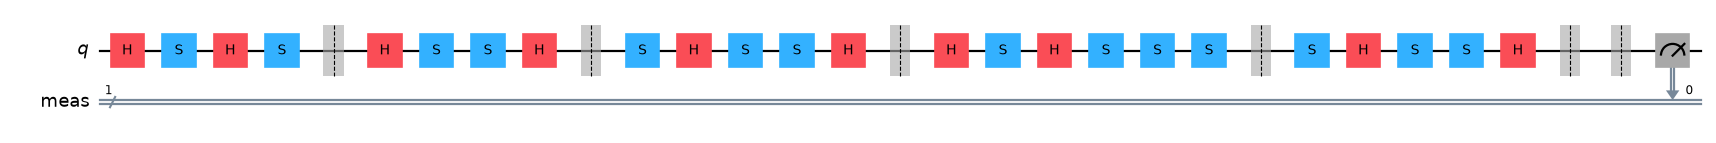

In [5]:
rng = np.random.default_rng(seed)
sequence = ops.random_sequence(4, rng)
print("Clifford indices:", sequence, "(the last one is the inverse)")

circuit = enc.build_circuit(sequence)
display(circuit.draw("mpl", fold=40, scale=0.8))
plt.close()

In the circuit above, each barrier ends one Clifford, and the last Clifford is the inverse of the four before it.

We check the inverse in code. A hand check is possible for a short case: the gate $S$ (index 2) followed by $S\,S\,S$ (index 10) is four $S$ gates. Two $S$ gates multiply the $|1\rangle$ amplitude by $i \cdot i = -1$, and four multiply it by $+1$, which is the identity. So the inverse of index 2 is index 10. The cell computes the inverse by the three moves and tests both that case and the printed sequence.

In [6]:
def inverse_index(indices):
    total = table[0][0]  # the identity
    for i in indices:
        total = total.compose(table[i][0])  # earlier Clifford acts first
    inverse = total.adjoint()
    return next(i for i, (c, _) in enumerate(table) if c == inverse)


print("inverse of index 2:", inverse_index([2]), "(hand check: 10)")

total = table[0][0]
for i in sequence:
    total = total.compose(table[i][0])
print("printed sequence composes to the identity:", total == table[0][0])
print(
    "last index found by the code:",
    sequence[-1],
    "| recomputed:",
    inverse_index(sequence[:-1]),
)

inverse of index 2: 10 (hand check: 10)
printed sequence composes to the identity: True
last index found by the code: 18 | recomputed: 18


Next we check that the circuit is the identity. Two circuits can differ by a **global phase**, a complex factor of size 1 that multiplies every amplitude. It changes no measurement probability, so counts cannot tell the circuits apart. `Operator.equiv` compares two matrices and ignores this factor. A measurement is not a matrix, so `remove_final_measurements` first strips it from a copy of the circuit. We then run the circuit with the measurement on a noiseless simulator.

In [7]:
from qiskit_aer import AerSimulator

unitary = Operator(circuit.remove_final_measurements(inplace=False))
print("equals the identity (up to a global phase):", unitary.equiv(Operator(np.eye(2))))

counts = AerSimulator().run(circuit, shots=1000).result().get_counts()
print("noiseless counts:", counts)

equals the identity (up to a global phase): True
noiseless counts: {'0': 1000}


**Stop and think.**

1. Why does the inverse make the test simple?

   **Answer.** The ideal answer is always 0, whatever the random gates were. A single number, the survival probability, then tells us about the noise.

2. Why must the compiler not shorten the sequence?

   **Answer.** The whole circuit is the identity, so an optimizer would delete it and we would measure nothing. `transpile_for` in `encoding.py` runs with the optimizer off, and the barriers mark the boundaries.

3. Why do we average over many sequences?

   **Answer.** One sequence fixes one particular order of gates, and its error can be better or worse than typical. The model above describes the average over the random choice, so we draw many sequences for each length.

## Step 3: Execution

Every sequence of every length is one circuit, so 10 lengths of 20 sequences make 200 circuits. They go out as **one job**, because on hardware the queue wait is paid once per job.

On the simulator the noise is a depolarizing error on each $H$ and $S$ and a read-out error. The decay rate that this noise gives follows from the numbers. Each gate multiplies the signal by $(1-e)$ (Setup), so a Clifford of $k$ gates multiplies it by $(1-e)^k$. A random Clifford is any of the 24 with equal probability, so $p$ is the average of $(1-e)^k$ over the table. The cell computes it. The value in the "built in" column of Step 4 is this number.

In [8]:
gate_counts = np.array([len(gates) for _, gates in table])  # k for each of the 24
e = ops.SIM_GATE_ERROR
print(
    f"k = 0 gates: (1 - e)^0 = {(1 - e) ** 0:.4f};  k = 6 gates: (1 - e)^6 = {(1 - e) ** 6:.4f}"
)
p_true = np.mean((1 - e) ** gate_counts)
print(f"p = average over the 24 of (1 - e)^k = {p_true:.5f}")
print(
    f"r = (1 - p) / 2 = {(1 - p_true) / 2:.5f}   (ops.simulator_truth gives {ops.simulator_truth()['epc']:.5f})"
)

k = 0 gates: (1 - e)^0 = 1.0000;  k = 6 gates: (1 - e)^6 = 0.9762
p = average over the 24 of (1 - e)^k = 0.98576
r = (1 - p) / 2 = 0.00712   (ops.simulator_truth gives 0.00712)


In [9]:
data = execution.run(
    lengths, sequences, shots, backend_name, qubit if backend_name else None, seed
)

print(f"{len(lengths) * sequences} circuits, {data['seconds']:.1f} s")
print(f"{'length':>7} {'mean survival':>14} {'spread (std)':>13}")
for m, runs in data["survival"].items():
    print(f"{m:>7} {np.mean(runs):>14.3f} {np.std(runs):>13.3f}")
print(f"\nshot noise at survival 0.5 with {shots} shots: {np.sqrt(0.25 / shots):.3f}")

200 circuits, 2.1 s
 length  mean survival  spread (std)
      1          0.967         0.006
      5          0.942         0.009
     10          0.912         0.014
     20          0.861         0.017
     40          0.769         0.016
     80          0.654         0.023
    120          0.594         0.018
    160          0.554         0.011
    240          0.526         0.017
    320          0.511         0.018

shot noise at survival 0.5 with 1000 shots: 0.016


The **spread (std)** is the standard deviation of the survival values of the 20 sequences of one length. It says how far a typical single sequence lies from the mean. **Shot noise** is the random scatter that comes from a finite number of repetitions. For a probability of 0.5 and 1000 shots it is $\sqrt{0.25/1000} = 0.016$. At long lengths the spread is close to this value, so there the sequences differ mainly by shot noise. At short lengths the survival is near 1 and shot noise is smaller, $\sqrt{F(1-F)/\text{shots}}$, which is 0.006 for $F = 0.97$. The measured spread there is about the same, so shot noise explains most of it at every length.

## Step 4: Analysis

### The fit

We average the survival over the sequences of each length and fit $A\,p^m + B$ to the averages with `scipy.optimize.curve_fit`, as in the benchmarking notebook. `curve_fit` also returns the covariance matrix, a table of numbers that says how far each fitted parameter could move and still fit the data about equally well. The square root of the diagonal entry for $p$ is the quoted error of $p$.

The first figure shows every sequence as a gray dot, the mean of each length with its error bar, and the fit. The error bar is the standard error of the mean, the spread divided by $\sqrt{20}$. For a spread of 0.015 it is 0.003. The lower panel shows the residuals, data minus fit. They should scatter around zero with no trend.

                                              fit   built in
decay rate p                      0.98574 +/- 0.00018    0.98576
error per Clifford r              0.00713 +/- 0.00009    0.00712
Clifford fidelity 1 - r           0.99287
error per gate                    0.00199 (3.58 gates per Clifford)
A, B                                0.466, 0.508


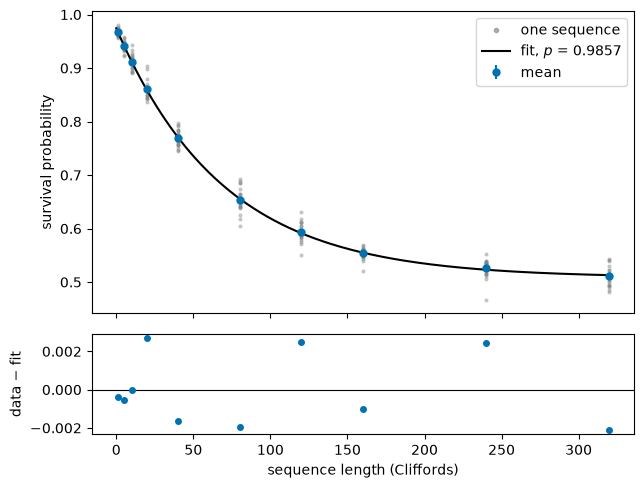

In [10]:
result = analysis.fit(data)
analysis.print_table(data, result)

fig = analysis.plot_fit(data, result)
display(fig)
plt.close(fig)

The table gives the decay rate $p$, the error per Clifford $r$, the fidelity $1 - r$, and the error per gate. On the simulator the column "built in" is the value computed in Step 3 from the noise we put in, and the fit should agree with it within a few standard errors.

### Does the read-out error matter?

Step 1 predicted that a read-out error changes $A$ and $B$ but not $p$. We test it by running the same gates with two read-out errors: none, and `p01` = 5% with `p10` = 10%. Step 1 gives the expected $A$ and $B$. A qubit in $|0\rangle$ is read as 0 with probability $1 - p_{01}$ and a qubit in $|1\rangle$ is read as 0 with probability $p_{10}$. The measured survival is $(1-p_{01})F + p_{10}(1-F) = p_{10} + (1 - p_{01} - p_{10})F$. With $F = \tfrac12 + \tfrac12 p^m$ this gives $A = (1 - 0.05 - 0.10)/2 = 0.425$ and $B = 0.10 + 0.425 = 0.525$.

The second figure shows the two cases on the same axes. Each case has its mean per length with error bars and its fitted curve, and the gray dots of single sequences are left out.

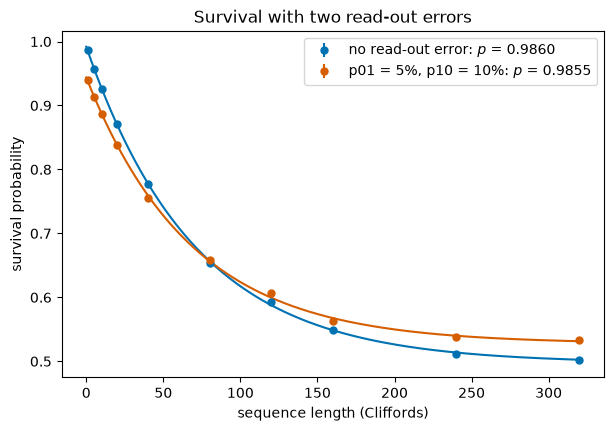

no read-out error          p = 0.9860 +/- 0.0002   A = 0.495   B = 0.497
p01 = 5%, p10 = 10%        p = 0.9855 +/- 0.0004   A = 0.416   B = 0.528


In [11]:
runs = {}
for label, readout in [
    ("no read-out error", (0.0, 0.0)),
    ("p01 = 5%, p10 = 10%", (0.05, 0.10)),
]:
    d = execution.run(lengths, sequences, shots, None, None, seed, readout=readout)
    runs[label] = (d, analysis.fit(d))

fig = analysis.plot_spam(runs)
display(fig)
plt.close(fig)

for label, (d, r) in runs.items():
    p, e = r["params"]["p"], r["errors"]["p"]
    print(
        f"{label:<26} p = {p:.4f} +/- {e:.4f}   A = {r['params']['amp']:.3f}   B = {r['params']['offset']:.3f}"
    )

The decay rates agree within about their combined errors, while $A$ and $B$ changed to about the predicted 0.425 and 0.525 (the 0.5 and 0.5 of the ideal case without read-out error). This is why RB is the standard way to quote gate fidelity: it separates the error of the gates from the error of preparing and reading the qubit. A test that applied one gate and compared the output would see the read-out error instead.

## Reading the results

- **The fit recovers the built-in error.** The fitted $p$ lies within a few standard errors of the built-in 0.9858, and the error per Clifford is about 0.7%. Try it: set `seed = 2` and rerun. The fit should move by about its error bar.
- **A and B are not 0.5.** The preparation and read-out errors move them, and the fit takes care of it. If $A$ were close to 0, the sequences would be too long and the curve would have decayed before the first point.
- **The error per gate is an estimate.** It divides the error per Clifford by the average gate count, which assumes all gates are equally bad. On hardware the compiler writes each Clifford in the device's **native gates**, the few gates the hardware performs directly ($\sqrt X$, $X$, and rotations about $Z$). The rotations about $Z$ are **virtual**: the device changes a software phase instead of sending a pulse, which costs no time and adds no error. The gate count is taken from the compiled circuits and leaves them out.
- **The number is an average.** It tells you about typical gates in random sequences. It does not tell you which gate is the worst or what kind of error it has. **Interleaved RB** (not covered here) measures one chosen gate by placing it between the random Cliffords and comparing the decay with plain RB.

On hardware, expect a curve that does not fall to exactly 0.5 within the longest sequence (choose longer sequences), and a spread between sequences that is larger than the shot noise alone. A residual pattern that is not scatter means the noise is not simple depolarizing. One cause is slow drift: the qubit's properties change over minutes, so later circuits see different noise than earlier ones.

## What to try next

1. Change `lengths` to `(1, 2, 4, 8, 16)`. The curve barely decays. What does the fit return for $p$, and how large is its error? What does this say about choosing the longest sequence?
2. Set `sequences = 5`, then `100`. How does the error of $p$ change?
3. In `ops.py` change `SIM_GATE_ERROR` to `0.01` and rerun. Predict $r$ first. Hint: recompute the average of $(1-e)^k$ over the table, as in Step 3, with $e = 0.01$, and use $r = (1-p)/2$.
4. Change `shots` to 100. Which part of the figure gets noisier, the spread within a length or the trend of the means?
5. Estimate the error per Clifford that comes from decoherence alone, $1 - e^{-t/T_2}$, where $t$ is the duration of a Clifford and $T_2$ is the value you measured in the benchmarking notebook. One-qubit gates on IBM devices take about 50 ns, and a Clifford has 3.58 gates, so $t \approx 3.58 \times 50\ \text{ns} = 180$ ns. For small $t/T_2$ the formula is close to $t/T_2$. Compare with $r$ from the fit. How do the gate error and the decoherence compare on `ibm_rensselaer`?
6. Run on `ibm_rensselaer` with `qubit = 0`, then a different qubit. Do the fidelities agree with the calibration page?
7. Hardware only: run twice on the same qubit. How large is the difference compared with the error bar of one fit?

## Terms

| Term | Plain definition | First used |
|---|---|---|
| Gate fidelity | A number from 0 to 1 that says how close a gate is to perfect; 1 is perfect | The problem |
| Survival probability | The chance of reading 0 at the end of a sequence that ideally returns $\lvert 0\rangle$ | The problem |
| Aer | Qiskit's simulator, which runs circuits on your computer with optional noise | Setup |
| Depolarizing error | With probability $e$ the state is replaced by a random one; the signal $F - \tfrac12$ is multiplied by $1-e$ | Setup |
| $S$ gate | Leaves $\lvert 0\rangle$ unchanged and multiplies the amplitude of $\lvert 1\rangle$ by $i$ | Setup |
| `p01`, `p10` | Chance that a 0 is read as 1, and that a 1 is read as 0 | Setup |
| Floor of 0.5 | The survival of a fully random state, which reads 0 half the time | Setup, Step 1 |
| Projector | The matrix $\lvert 0\rangle\langle 0\rvert$ whose expectation value is the probability of reading 0 | Step 1 |
| Clifford | One of 24 single-qubit gates that send each of the six states $\lvert 0\rangle, \lvert 1\rangle, \lvert +\rangle, \lvert -\rangle, \lvert {+i}\rangle, \lvert {-i}\rangle$ to another of them | Step 1 |
| Closed set | A set of gates where any gate applied after any other is again in the set | Step 1 |
| Decay rate $p$ | The fraction of the signal that survives one Clifford | Step 1 |
| Error per Clifford $r$ | $(1-p)/2$, the part of the output that is wrong per Clifford | Step 1 |
| Barrier | A marker that stops the compiler from combining gates across it | Step 2 |
| Compile (transpile) | Rewrite a circuit in the gates a device supports | Step 2 |
| Optimizer | A compiler stage that simplifies circuits by merging or deleting gates | Step 2 |
| Global phase | A complex factor of size 1 on all amplitudes; it changes no probability | Step 2 |
| Spread (std) | Standard deviation of the survival of the sequences of one length | Step 3 |
| Shot noise | Random scatter from a finite number of repetitions | Step 3 |
| Covariance matrix | Table from `curve_fit` whose diagonal gives the squared error of each fitted parameter | Step 4 |
| Residual | Data minus fit | Step 4 |
| Native gates | The gates the hardware performs directly | Reading the results |
| Virtual rotation about $Z$ | A software phase change that costs no time and adds no error | Reading the results |
| Interleaved RB | RB with one chosen gate placed between the random Cliffords, to benchmark that gate | Reading the results |
| Slow drift | Qubit properties changing over minutes | Reading the results |